# 02 — Da seleção fotométrica à validação espectroscópica

Workshop SAB — AI-Scope / ADSS

**Pergunta científica:** depois de selecionar candidatos em um catálogo, quais deles possuem informação espectroscópica independente?

O exemplo usa uma tabela local de alvos e faz o crossmatch no servidor com DESI DR1. Isso evita baixar um catálogo espectroscópico inteiro apenas para cruzá-lo localmente.
`upload.targets` é a tabela temporária enviada em `file=targets`. `cone` compara posições em graus; `dist` mede a separação angular para examinar a qualidade da associação.

### DESI — DESI DR1 / SpecZ
O **DESI** (Dark Energy Spectroscopic Instrument) é um espectrógrafo multiobjeto instalado no telescópio Mayall de 4 metros, no Arizona.

- **Instrumento:** 5.000 posicionadores de fibras ópticas e espectrógrafos com três braços (B, R e Z).
- **Dados:** espectros ópticos, redshifts e classificações espectrais.
- **DESI SpecZ:** catálogo com redshifts (`z`), incertezas (`zerr`), indicadores de qualidade (`zwarn`) e classificações (`spectype`).
- **DESI DR1:** https://data.desi.lbl.gov/doc/releases/dr1/


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import adss

BASE_URL = "https://ai-scope.cbpf.br/"

cl = adss.ADSSClient(base_url=BASE_URL)

In [2]:
# Use a saída do notebook anterior ou substitua por sua própria lista de alvos.
# Exemplo mínimo para permitir execução independente:
targets = pd.read_csv("outputs/cluster_1.csv")

In [3]:
targets

,source_id,ra,dec,radius_deg,pmra,pmdec,pmra_error,pmdec_error,parallax,parallax_error,phot_g_mean_mag,phot_bp_mean_mag,phot_rp_mean_mag,bp_rp,ruwe,kinematic_excess
0,2686840521431628288,323.324139,-0.880722,0.069110,3.535957,-2.173133,0.114538,0.073543,0.008011,0.113313,17.320658,17.716633,16.747751,0.968882,0.979177,2.002077
1,2686842033259327104,323.216615,-0.902025,0.165845,3.540397,-2.169961,0.119509,0.083477,-0.033886,0.115138,17.649788,18.056982,17.079865,0.977118,1.053021,2.002068
2,2686841208630066176,323.323723,-0.850133,0.047235,3.523109,-2.172632,0.082432,0.045770,-0.009831,0.066133,16.312115,16.360470,16.273584,0.086885,1.005163,2.002033
3,2686843579447556992,323.253369,-0.887782,0.126833,3.523987,-2.174720,0.123127,0.080571,0.130173,0.114084,17.476366,17.879677,16.900747,0.978930,1.036951,2.002006
4,2686850245241277696,323.344394,-0.804620,0.026083,3.551845,-2.166595,0.198749,0.100412,0.172955,0.130352,17.393589,17.130636,16.252893,0.877743,1.163365,2.001873
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
353,2686844266646783872,323.328537,-0.826074,0.034172,3.608585,-2.083400,0.051430,0.030223,-0.021024,0.043483,15.561186,15.965014,14.886327,1.078688,0.935104,1.984347
354,2686846950998135552,323.372174,-0.839668,0.018962,3.343826,-2.173708,0.085897,0.042853,-0.241768,0.059241,16.045662,15.896893,15.394764,0.502129,1.094846,1.984327
355,2686846946706465792,323.383652,-0.838759,0.026117,3.350035,-2.112683,0.082595,0.038944,-0.121880,0.050212,15.921176,15.863598,15.545351,0.318247,0.917976,1.984300
356,2686890343051497344,323.139072,-0.840369,0.224155,3.366053,-2.096690,0.108775,0.088214,0.111751,0.103947,17.169144,17.575636,16.587310,0.988325,1.030786,1.984230


### Consulta de redshifts DESI

Utilizando **astroql**, associe os objetos da tabela `upload.targets` ao catálogo espectroscópico `desi.desi_specz_dr1`, buscando correspondências dentro de um raio de **0,0003° (~1,08")**.

A consulta deve retornar:
- **Identificação:** ID Gaia (`source_id`) e ID DESI (`id`).
- **Coordenadas:** RA e Dec dos dois catálogos.
- **Espectroscopia:** `z`, `zerr`, `zwarn`, `spectype`, `subtype` e `deltachi2`.
- **Separação angular:** distância entre os objetos em graus. Dica: utilize `dist(dist(u.ra, u.dec, d.ra, d.dec) AS separation_deg)` como uma coluna para calcular a separação angular.

**Dicas:**
- Utilize `JOIN` para associar as tabelas.
- Utilize `cone()` para encontrar correspondências espaciais.
- Utilize `dist()` para calcular a separação angular.
- Utilize aliases (`AS`) para diferenciar as colunas dos catálogos.

**Atenção:** mantenha os aliases (renomear as colunas) `input_source_id`, `input_ra`, `input_dec`, `desi_id`, `desi_ra`, `desi_dec` e `separation_deg`, pois serão utilizados na análise seguinte.

In [4]:
metadata = cl.get_database_metadata()

table = metadata.get_table("desi", "desi_specz_dr1")
if table is not None:
    print(table.column_names())

['id', 'survey', 'program', 'firstnight', 'lastnight', 'spgrpval', 'z', 'zerr', 'zwarn', 'chi2', 'coeff', 'npixels', 'spectype', 'subtype', 'ncoeff', 'deltachi2', 'petal_loc', 'device_loc', 'location', 'fiber', 'coadd_fiberstatus', 'ra', 'dec', 'pmra', 'pmdec', 'ref_epoch', 'lambda_ref', 'fa_target', 'fa_type', 'objtype', 'fiberassign_x', 'fiberassign_y', 'priority', 'subpriority', 'obsconditions', 'release', 'brickname', 'brickid', 'brick_objid', 'morphtype', 'ebv', 'flux_g', 'flux_r', 'flux_z', 'flux_w1', 'flux_w2', 'flux_ivar_g', 'flux_ivar_r', 'flux_ivar_z', 'flux_ivar_w1', 'flux_ivar_w2', 'fiberflux_g', 'fiberflux_r', 'fiberflux_z', 'fibertotflux_g', 'fibertotflux_r', 'fibertotflux_z', 'maskbits', 'sersic', 'shape_r', 'shape_e1', 'shape_e2', 'ref_id', 'ref_cat', 'gaia_phot_g_mean_mag', 'gaia_phot_bp_mean_mag', 'gaia_phot_rp_mean_mag', 'parallax', 'photsys', 'priority_init', 'numobs_init', 'cmx_target', 'desi_target', 'bgs_target', 'mws_target', 'scnd_target', 'sv1_desi_target', 's

In [5]:
query = """
SELECT
    u.source_id AS input_source_id,
    u.ra AS input_ra,
    u.dec AS input_dec,
    d.id AS desi_id,
    d.ra AS desi_ra,
    d.dec AS desi_dec,
    d.z,
    d.zerr,
    d.zwarn,
    d.spectype,
    d.subtype,
    d.deltachi2,
    dist(u.ra, u.dec, d.ra, d.dec) AS separation_deg
FROM upload.targets AS u
JOIN desi.desi_specz_dr1 AS d
  ON cone(d.ra, d.dec, u.ra, u.dec, 0.0003)
""" 
if not query:
    raise NotImplementedError("Complete a query;")

spec = cl.query_and_wait(
    query_text=query,
    mode="astroql",
    file=targets,
    table_name="targets123",
).data

spec.head()

Check query status at: https://ai-scope.cbpf.br/queries/a790d272-7848-4931-b8ae-7934b1402fd3
Results fetched.


,input_source_id,input_ra,input_dec,desi_id,desi_ra,desi_dec,z,zerr,zwarn,spectype,subtype,deltachi2,separation_deg
0,2686840521431628288,323.324139,-0.880722,39627765992917818,323.324138,-0.880721,-0.000003,0.000004,0,STAR,K,8585.761256,5.941939e-07
1,2686843579447556992,323.253369,-0.887782,39627765992915165,323.253368,-0.887782,-0.000002,0.000007,0,STAR,K,3966.904018,6.009414e-07
2,2686837532134243712,323.306218,-0.993540,39627765992917090,323.306217,-0.993540,-0.000010,0.000010,0,STAR,G,1589.148057,5.581023e-07
3,2686723835760473856,323.226243,-1.277436,39627759948931395,323.226242,-1.277436,-0.000019,0.000003,0,STAR,K,14490.750945,5.956875e-07
4,2686845885849204096,323.427131,-0.867275,39627772032727977,323.427130,-0.867275,0.000019,0.000005,0,STAR,K,6164.995717,5.574753e-07


spectype
STAR    20
Name: count, dtype: int64


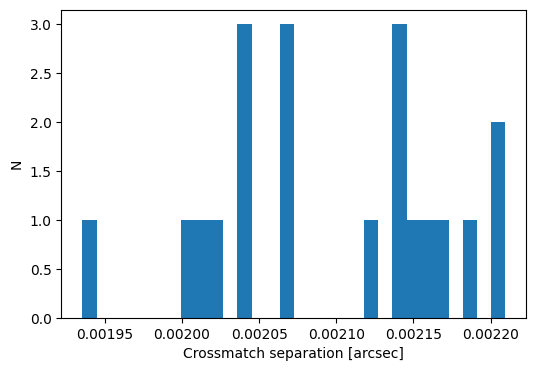

In [6]:
spec["separation_arcsec"] = spec.separation_deg * 3600
print(spec.spectype.value_counts(dropna=False))

fig, ax = plt.subplots(figsize=(6,4))
ax.hist(spec.separation_arcsec.dropna(), bins=30)
ax.set(xlabel="Crossmatch separation [arcsec]", ylabel="N")
plt.show()

### Espectros DESI dos objetos associados

O catálogo `desi.desi_specz_dr1` fornece a classificação e o redshift. Os arrays espectrais estão em `desi.desi_dr1`, ligados por `desi_id = targetid`. Consultamos apenas os IDs encontrados acima e incluímos as três câmeras (B, R e Z).

`wave_*` contém comprimentos de onda, `flux_*` o fluxo espectral e `ivar_*` a **variância inversa** em cada pixel. Um pixel com `ivar <= 0` não tem peso útil no gráfico. As bandas B/R/Z são braços do espectrógrafo, não filtros fotométricos.

Agora associe os IDs únicos de `upload.desitargets` a `desi.desi_dr1` por `desi_id = targetid`. Selecione `wave`, `flux` e `ivar` para B, R e Z, além do ID. O nome da tabela carregada no ADSS deve coincidir com `table_name="desitargets"`.


In [7]:
metadata = cl.get_database_metadata()

table = metadata.get_table("desi", "desi_dr1")
if table is not None:
    print(table.column_names())

['targetid', 'ra', 'dec', 'pmra', 'pmdec', 'ref_epoch', 'objtype', 'ebv', 'ls_flux_g', 'ls_flux_r', 'ls_flux_z', 'ls_flux_w1', 'ls_flux_w2', 'ls_flux_ivar_g', 'ls_flux_ivar_r', 'ls_flux_ivar_z', 'ls_flux_ivar_w1', 'ls_flux_ivar_w2', 'ls_fiberflux_g', 'ls_fiberflux_r', 'ls_fiberflux_z', 'ls_fibertotflux_g', 'ls_fibertotflux_r', 'ls_fibertotflux_z', 'coadd_numexp', 'coadd_exptime', 'coadd_numtile', 'mean_fiber_ra', 'mean_fiber_dec', 'mean_psf_to_fiber_specflux', 'flux_b', 'ivar_b', 'wave_b', 'flux_r', 'ivar_r', 'wave_r', 'flux_z', 'ivar_z', 'wave_z']


In [8]:
# Fetch one spectral row per matched DESI target, including all three arms.
desi_targets = spec[["desi_id", "desi_ra", "desi_dec"]].dropna().drop_duplicates(subset="desi_id")

spectra_query = """
SELECT
    u.desi_id,
    s.wave_b, s.flux_b, s.ivar_b,
    s.wave_r, s.flux_r, s.ivar_r,
    s.wave_z, s.flux_z, s.ivar_z
FROM upload.desitargets AS u
JOIN desi.desi_dr1 AS s ON s.targetid = u.desi_id
"""

if not spectra_query:
    raise NotImplementedError("Complete spectra_query;")

spectra = cl.query_and_wait(
    query_text=spectra_query,
    mode="astroql",
    file=desi_targets,
    table_name="desitargets",
).data

print(f"Matched DESI IDs: {len(desi_targets)}; spectra returned: {len(spectra)}")


Check query status at: https://ai-scope.cbpf.br/queries/a9b9e4e8-543c-4e95-89b7-dd59fc9bdf88
Results fetched.
Matched DESI IDs: 18; spectra returned: 20


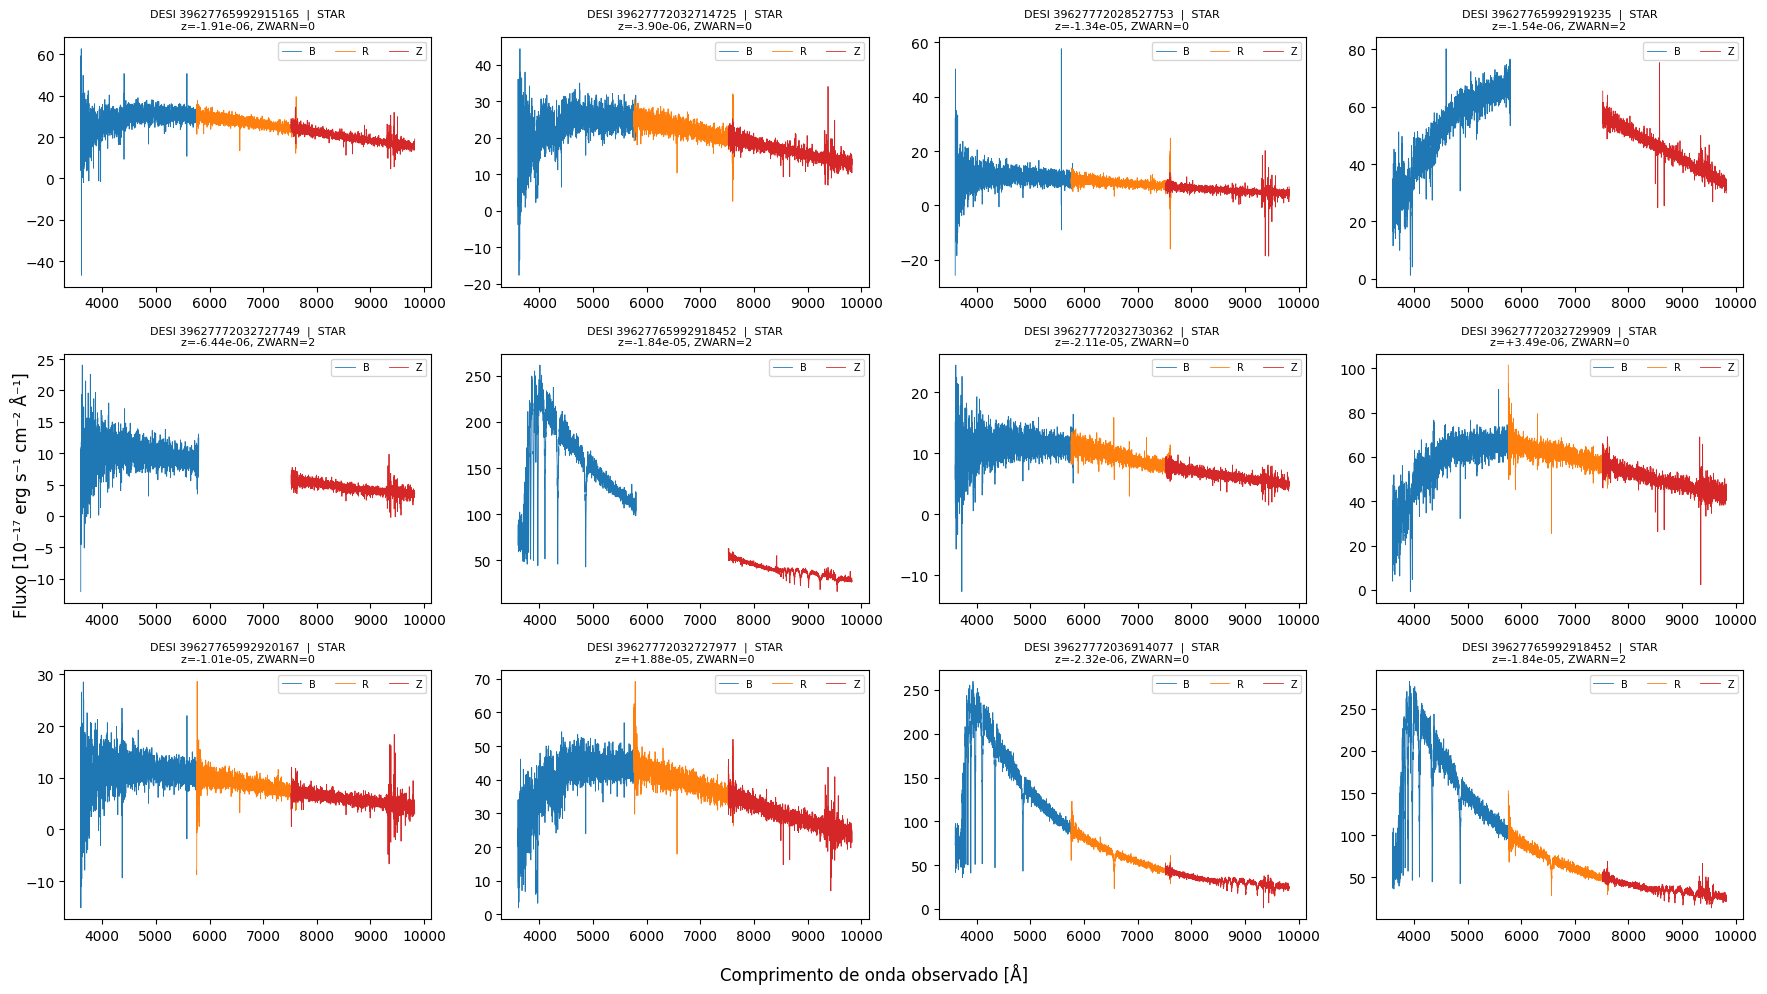

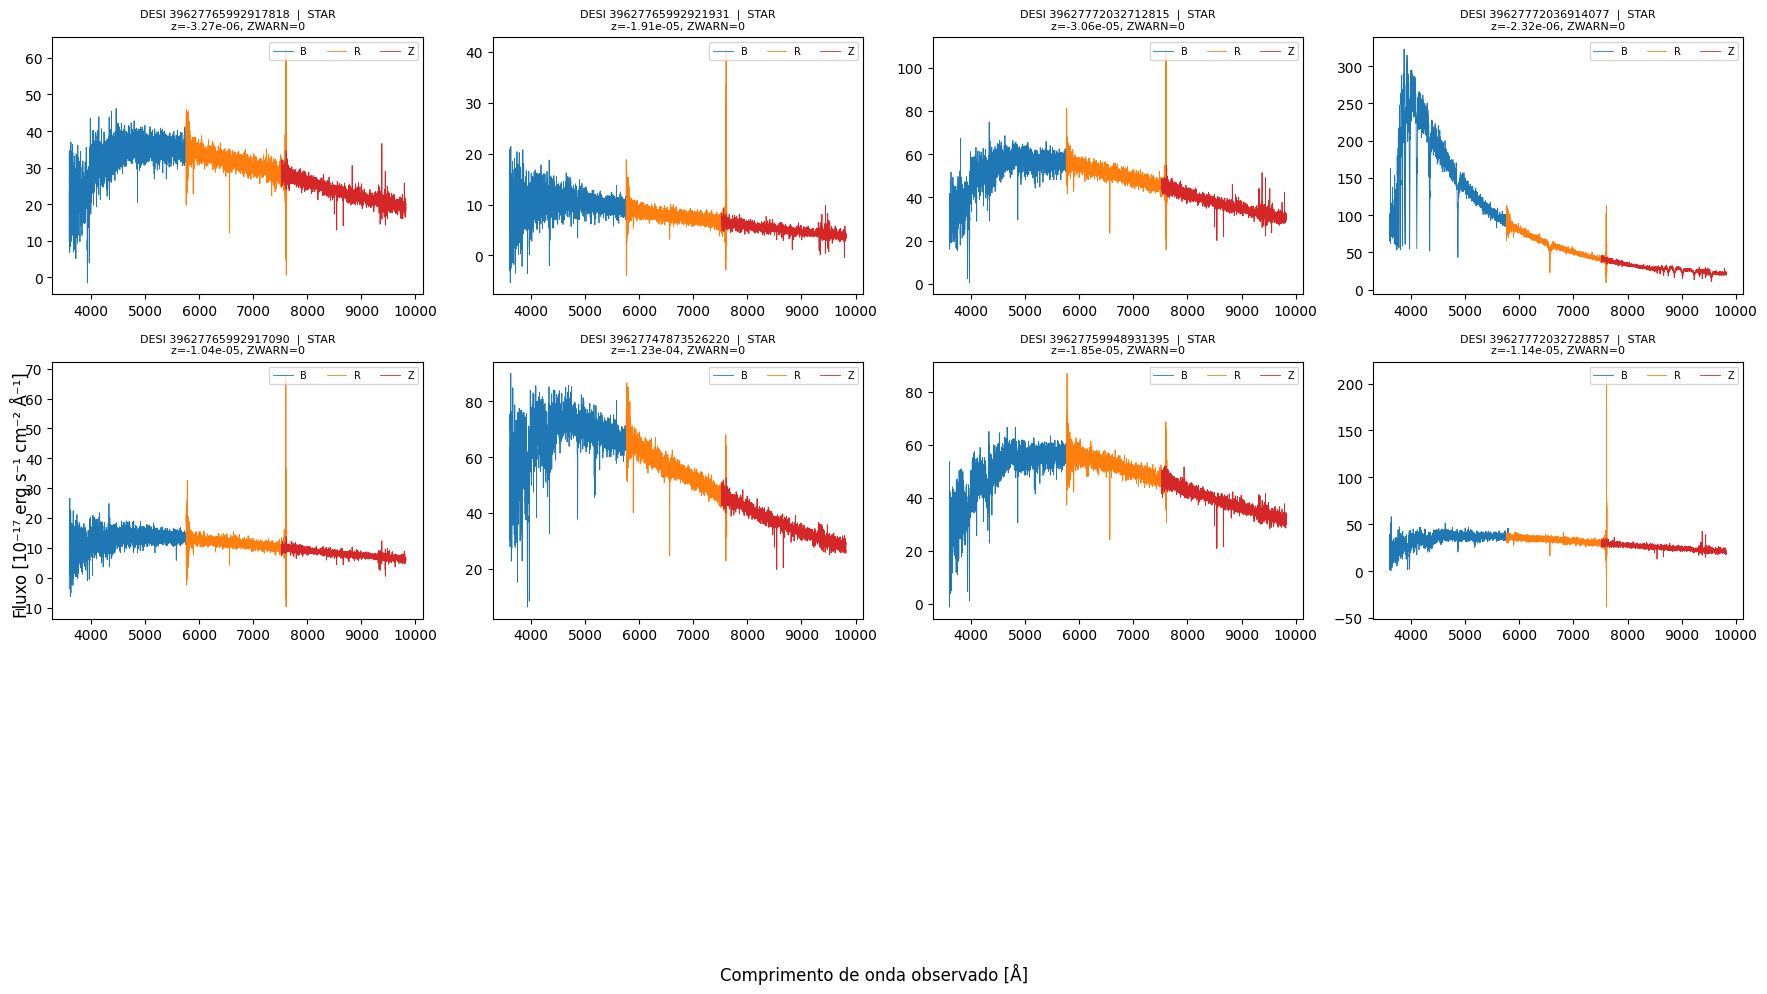

Espectros desenhados: 20 de 20 linhas retornadas


In [9]:
# Um alvo DESI pode aparecer em mais de uma linha; associe um z por ID.
specz_by_id = (spec.assign(desi_id=spec["desi_id"].astype("string"))
               .sort_values("separation_deg")
               .drop_duplicates("desi_id")
               [["desi_id", "input_source_id", "z", "zerr", "zwarn",
                 "spectype", "subtype", "deltachi2"]].copy())
specz_by_id["z"] = pd.to_numeric(specz_by_id["z"], errors="coerce")
specz_by_id["zerr"] = pd.to_numeric(specz_by_id["zerr"], errors="coerce")
specz_by_id["zwarn"] = pd.to_numeric(specz_by_id["zwarn"], errors="coerce")
spectra_with_z = spectra.assign(desi_id=spectra["desi_id"].astype("string")).merge(
    specz_by_id, on="desi_id", how="left", validate="many_to_one"
)

# Cada painel mostra os três braços do espectro e o resultado do ajuste DESI.
arms = {"b": "tab:blue", "r": "tab:orange", "z": "tab:red"}
page_size = 12
plotted = 0
for start in range(0, len(spectra_with_z), page_size):
    page = spectra_with_z.iloc[start:start + page_size]
    fig, axes = plt.subplots(3, 4, figsize=(18, 10), squeeze=False)
    for ax, (_, row) in zip(axes.flat, page.iterrows()):
        n_arms = 0
        for arm, color in arms.items():
            values = [row[f"{quantity}_{arm}"] for quantity in ("wave", "flux", "ivar")]
            if any(value is None for value in values):
                continue
            wave, flux, ivar = (np.asarray(value, dtype=float) for value in values)
            if wave.ndim != 1 or wave.shape != flux.shape or wave.shape != ivar.shape:
                continue
            valid = np.isfinite(wave) & np.isfinite(flux) & np.isfinite(ivar) & (ivar > 0)
            if valid.any():
                ax.plot(wave[valid], flux[valid], color=color, lw=0.6, label=arm.upper())
                n_arms += 1
        z_label = f"z={row.z:+.2e}" if pd.notna(row.z) else "z indisponível"
        ax.set_title(f"DESI {row.desi_id}  |  {row.spectype}\n{z_label}, ZWARN={row.zwarn}",
                     fontsize=8)
        if n_arms:
            ax.legend(fontsize=7, ncol=3, loc="upper right")
            plotted += 1
        else:
            ax.text(0.5, 0.5, "Sem pixels válidos", ha="center", va="center",
                    transform=ax.transAxes)
    for ax in axes.flat[len(page):]:
        ax.set_visible(False)
    fig.supxlabel("Comprimento de onda observado [Å]")
    fig.supylabel("Fluxo [10⁻¹⁷ erg s⁻¹ cm⁻² Å⁻¹]")
    fig.tight_layout()
    plt.show()
print(f"Espectros desenhados: {plotted} de {len(spectra_with_z)} linhas retornadas")


### `specz` para candidatos estelares

O `z` em `desi.desi_specz_dr1` é o ajuste espectral do Redrock. Para objetos classificados `STAR`, ele fica perto de zero; na aproximação de baixa velocidade, `v ≈ c z` ajuda a enxergar diferenças de poucos km/s. A figura mostra `z` contra a distância angular ao centro de M2 e a distribuição de `v ≈ c z` para alvos com `SPECTYPE=STAR` e `ZWARN=0`. Cada alvo DESI entra uma vez no resumo, mesmo que haja linhas repetidas no crossmatch ou nos espectros.

Isso é uma **checagem adicional**, não uma confirmação automática de pertença ao aglomerado: o crossmatch, a classificação, a incerteza e a distribuição de velocidades precisam ser avaliados. `ZWARN=0` indica ausência de avisos conhecidos do ajuste, não precisão garantida. Para velocidades radiais estelares de melhor qualidade, a [DESI DR1 Milky Way Survey VAC](https://data.desi.lbl.gov/doc/releases/dr1/vac/mws/) fornece medidas próprias de RVSpecFit; a [página de DR1](https://data.desi.lbl.gov/doc/releases/dr1/) descreve `SPECTYPE`, `ZWARN` e os três braços espectrais.


Alvos DESI únicos: 18; estrelas com ZWARN=0 e z finito: 15


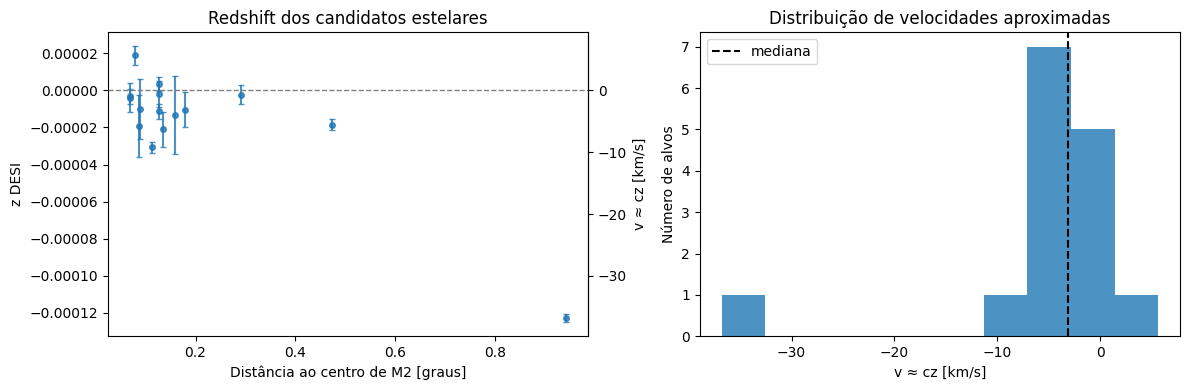

,input_source_id,desi_id,spectype,z,zerr,zwarn,v_approx_km_s,radius_deg
15,2686479611035078528,39627747873526220,STAR,-0.000123,0.000002,0,-36.793473,0.942547
7,2686845297434516480,39627772032712815,STAR,-0.000031,0.000003,0,-9.188073,0.112888
9,2686846573044438656,39627772032730362,STAR,-0.000021,0.000009,0,-6.317703,0.135536
0,2686839937316045184,39627765992921931,STAR,-0.000019,0.000017,0,-5.728743,0.086766
12,2686723835760473856,39627759948931395,STAR,-0.000019,0.000003,0,-5.550609,0.474159
17,2686839250121195392,39627765992918452,STAR,-0.000018,0.000003,2,-5.529896,0.128291
3,2686843201490449280,39627772028527753,STAR,-0.000013,0.000021,0,-4.027154,0.158919
13,2686852414199399296,39627772032728857,STAR,-0.000011,0.000004,0,-3.409746,0.127167
2,2686837532134243712,39627765992917090,STAR,-0.000010,0.000010,0,-3.108163,0.179332
16,2686840006035487360,39627765992920167,STAR,-0.000010,0.000016,0,-3.037948,0.089648


In [10]:
C_KM_S = 299792.458
star_z = specz_by_id.merge(
    targets[["source_id", "radius_deg"]].rename(columns={"source_id": "input_source_id"}),
    on="input_source_id", how="left", validate="many_to_one",
)
star_z["radius_deg"] = pd.to_numeric(star_z["radius_deg"], errors="coerce")
star_z["v_approx_km_s"] = C_KM_S * star_z["z"]
good = (star_z["spectype"].eq("STAR") & star_z["zwarn"].eq(0)
        & np.isfinite(star_z["z"]) & np.isfinite(star_z["radius_deg"]))
good_stars = star_z.loc[good].copy()
print(f"Alvos DESI únicos: {len(star_z)}; estrelas com ZWARN=0 e z finito: {len(good_stars)}")

if good_stars.empty:
    print("Nenhum z estelar de boa qualidade para mostrar.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    zerr = good_stars["zerr"].fillna(0).clip(lower=0)
    axes[0].errorbar(good_stars["radius_deg"], good_stars["z"], yerr=zerr,
                     fmt="o", ms=4, capsize=2, alpha=0.8)
    axes[0].axhline(0, color="0.5", ls="--", lw=1)
    axes[0].set(xlabel="Distância ao centro de M2 [graus]", ylabel="z DESI",
                title="Redshift dos candidatos estelares")
    velocity_axis = axes[0].secondary_yaxis(
        "right", functions=(lambda z: C_KM_S * z, lambda v: v / C_KM_S)
    )
    velocity_axis.set_ylabel("v ≈ cz [km/s]")

    axes[1].hist(good_stars["v_approx_km_s"], bins=min(10, max(3, len(good_stars))),
                 color="tab:blue", alpha=0.8)
    axes[1].axvline(good_stars["v_approx_km_s"].median(), color="black", ls="--",
                    label="mediana")
    axes[1].set(xlabel="v ≈ cz [km/s]", ylabel="Número de alvos",
                title="Distribuição de velocidades aproximadas")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

display(star_z[["input_source_id", "desi_id", "spectype", "z", "zerr",
                "zwarn", "v_approx_km_s", "radius_deg"]].sort_values("z"))


### Investigação

Compare os espectros, `SPECTYPE`, `ZWARN` e `z` dos candidatos. Os objetos com velocidade discrepante podem ser contaminantes ou ter ajustes problemáticos; examine também posição, movimentos próprios e qualidade do espectro. O valor `v ≈ cz` é uma aproximação didática, não uma medida dedicada de velocidade radial estelar.
